In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from scipy.optimize import nnls

In [3]:
#Leer datos
metanol = pd.read_csv("Metanol.csv", skiprows=1)
etanol = pd.read_csv("Etanol.csv", skiprows=1)
isopropanol = pd.read_csv("Isopropanol.csv", skiprows=1)
muestra = pd.read_csv("Muestra E-Cespedes-Gonzalez.csv", skiprows=1)

In [4]:
print(muestra.head())
print(muestra.shape)

     cm-1     %T
0  4000.0  99.60
1  3999.0  99.58
2  3998.0  99.57
3  3997.0  99.57
4  3996.0  99.58
(3451, 2)


In [ ]:
#Procesamiento de transmitancia a absorbancia 
metanol["Absorbancia"] = np.log10(100 / metanol["%T"])
etanol["Absorbancia"] = np.log10(100 / etanol["%T"])
isopropanol["Absorbancia"] = np.log10(100 / isopropanol["%T"])
muestra["Absorbancia"] = np.log10(100 / muestra["%T"])

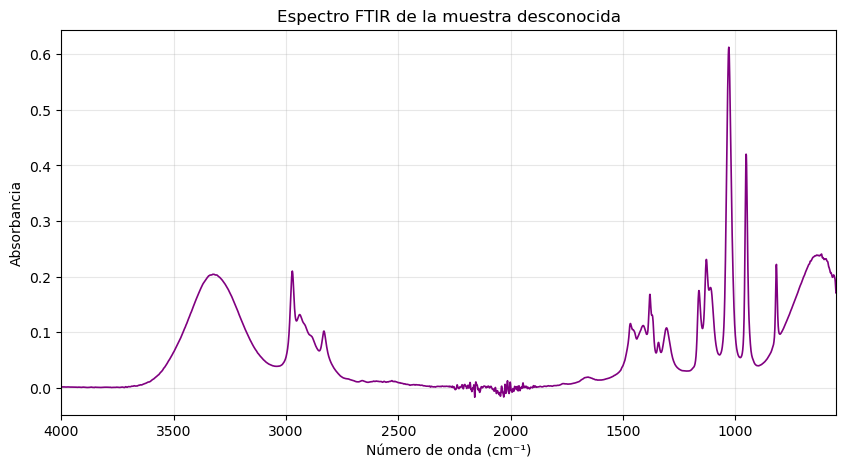

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(muestra["cm-1"], muestra["Absorbancia"],
         color="purple", linewidth=1.2)

plt.xlabel("Número de onda (cm⁻¹)")
plt.ylabel("Absorbancia")
plt.title("Espectro FTIR de la muestra desconocida")

plt.xlim(4000, 550)
plt.grid(alpha=0.3)

plt.show()

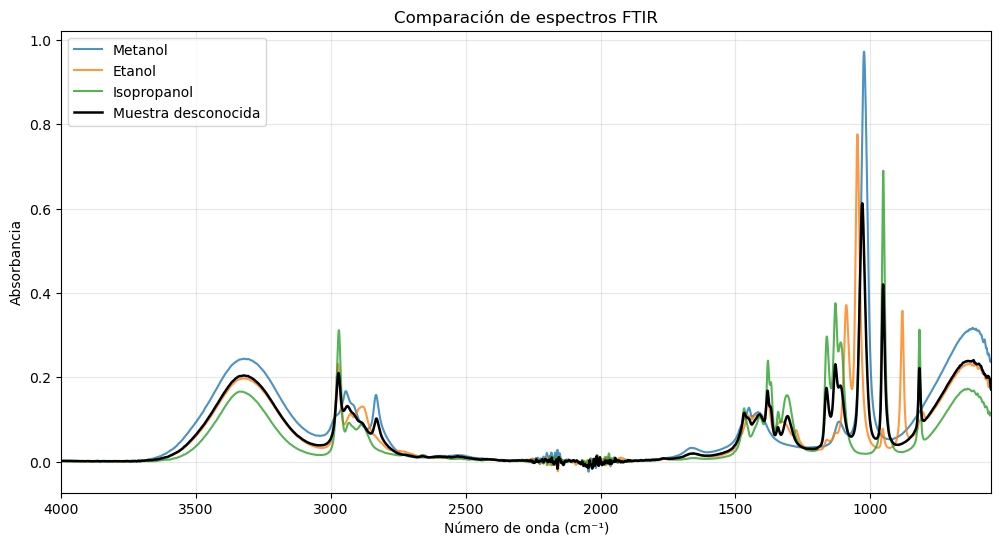

In [15]:
plt.figure(figsize=(12, 6))

plt.plot(metanol["cm-1"], metanol["Absorbancia"],
         label="Metanol", alpha=0.8)

plt.plot(etanol["cm-1"], etanol["Absorbancia"],
         label="Etanol", alpha=0.8)

plt.plot(isopropanol["cm-1"], isopropanol["Absorbancia"],
         label="Isopropanol", alpha=0.8)

plt.plot(muestra["cm-1"], muestra["Absorbancia"],
         label="Muestra desconocida",
         color="black", linewidth=1.8)

plt.xlabel("Número de onda (cm⁻¹)")
plt.ylabel("Absorbancia")
plt.title("Comparación de espectros FTIR")

plt.xlim(4000, 550)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

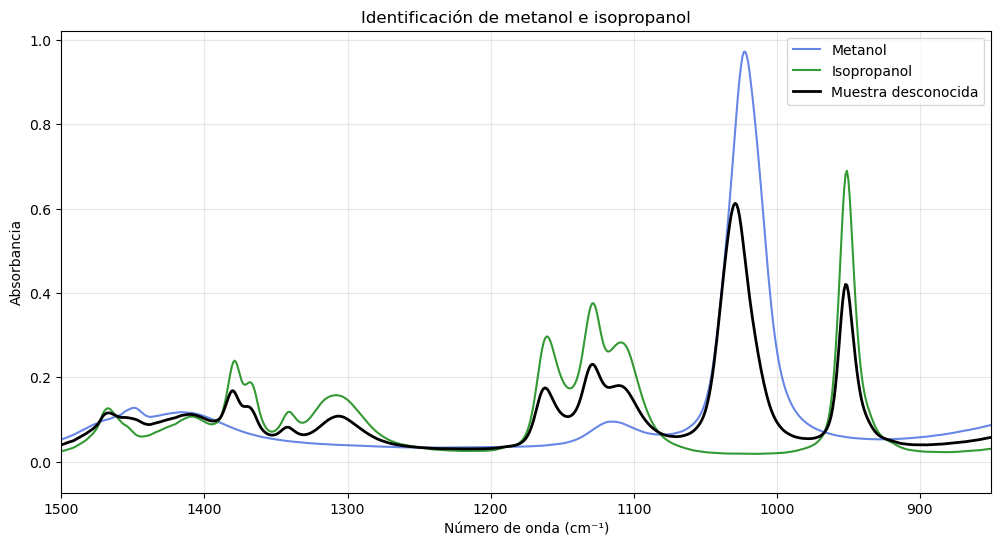

In [16]:
plt.figure(figsize=(12, 6))

plt.plot(metanol["cm-1"], metanol["Absorbancia"],
         label="Metanol", color="royalblue", alpha=0.8)

plt.plot(isopropanol["cm-1"], isopropanol["Absorbancia"],
         label="Isopropanol", color="green", alpha=0.8)

plt.plot(muestra["cm-1"], muestra["Absorbancia"],
         label="Muestra desconocida", color="black",
         linewidth=2)

plt.xlim(1500, 850)

plt.xlabel("Número de onda (cm⁻¹)")
plt.ylabel("Absorbancia")
plt.title("Identificación de metanol e isopropanol")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
#Función para encontrar los picos de la función en una región específica dada
from scipy.signal import find_peaks, savgol_filter

def detectar_picos(datos):
    # Seleccionar la región de interés
    region = datos[
        (datos["cm-1"] >= 850) &
        (datos["cm-1"] <= 1500)
    ]

    x = region["cm-1"].to_numpy()
    y = region["Absorbancia"].to_numpy()

    # Suavizar ligeramente el espectro
    y_suave = savgol_filter(y, 11, 3)

    # Encontrar máximos locales
    indices, propiedades = find_peaks(
        y_suave,
        prominence=0.025,
        distance=12
    )

    return pd.DataFrame({
        "Número de onda": x[indices],
        "Absorbancia": y_suave[indices]
    })

In [ ]:
#Implementación de la función para encontrar los picos

# Detectar picos
picos_metanol = detectar_picos(metanol)
picos_etanol = detectar_picos(etanol)
picos_isopropanol = detectar_picos(isopropanol)
picos_muestra = detectar_picos(muestra)

# Unir las tablas horizontalmente
tabla_picos = pd.concat(
    [
        picos_metanol.reset_index(drop=True),
        picos_etanol.reset_index(drop=True),
        picos_isopropanol.reset_index(drop=True),
        picos_muestra.reset_index(drop=True)
    ],
    axis=1,
    keys=["METANOL", "ETANOL", "ISOPROPANOL", "MUESTRA"]
)

# Mostrar tabla con estilo
display(
    tabla_picos.style
    .format(precision=2, na_rep="—")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#EADCF8"),
                ("color", "#3F2857"),
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("padding", "8px"),
                ("border-bottom", "1px solid #E8E2F0")
            ]
        }
    ])
    .hide(axis="index")
)



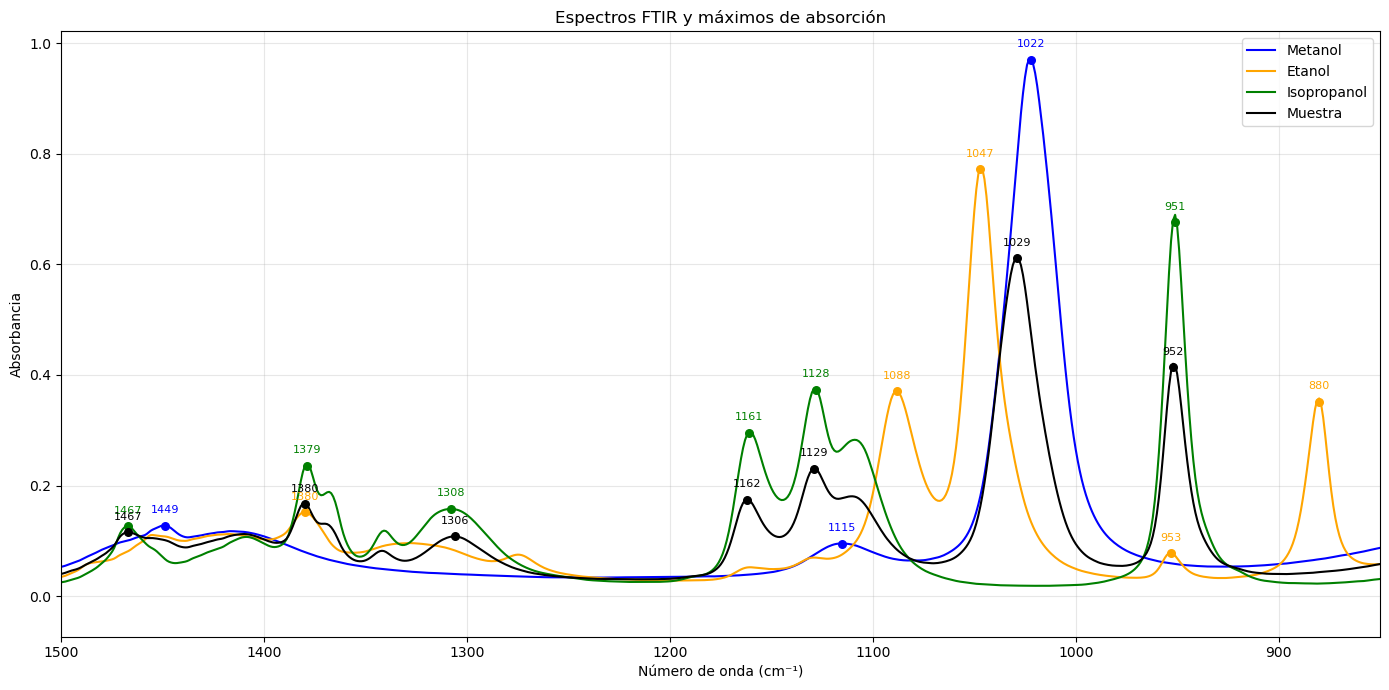

In [ ]:
#Gráfica de los picos obtenidos para la región específicada


plt.figure(figsize=(14, 7))

espectros = [
    (metanol, picos_metanol, "Metanol", "blue"),
    (etanol, picos_etanol, "Etanol", "orange"),
    (isopropanol, picos_isopropanol, "Isopropanol", "green"),
    (muestra, picos_muestra, "Muestra", "black")
]

for datos, picos, nombre, color in espectros:

    # Graficar el espectro
    plt.plot(
        datos["cm-1"],
        datos["Absorbancia"],
        color=color,
        label=nombre
    )

    # Marcar sus máximos
    plt.scatter(
        picos["Número de onda"],
        picos["Absorbancia"],
        color=color,
        s=30,
        zorder=5
    )

    # Escribir el número de onda de cada máximo
    for _, fila in picos.iterrows():
        plt.annotate(
            f"{fila['Número de onda']:.0f}",
            (fila["Número de onda"], fila["Absorbancia"]),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            color=color
        )

plt.xlim(1500, 850)
plt.xlabel("Número de onda (cm⁻¹)")
plt.ylabel("Absorbancia")
plt.title("Espectros FTIR y máximos de absorción")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

RESULTADOS DEL AJUSTE
Coeficiente metanol: 0.5172
Coeficiente isopropanol: 0.5045
Metanol: 50.62%
Isopropanol: 49.38%
Razón metanol/isopropanol: 1.025
R²: 0.95537


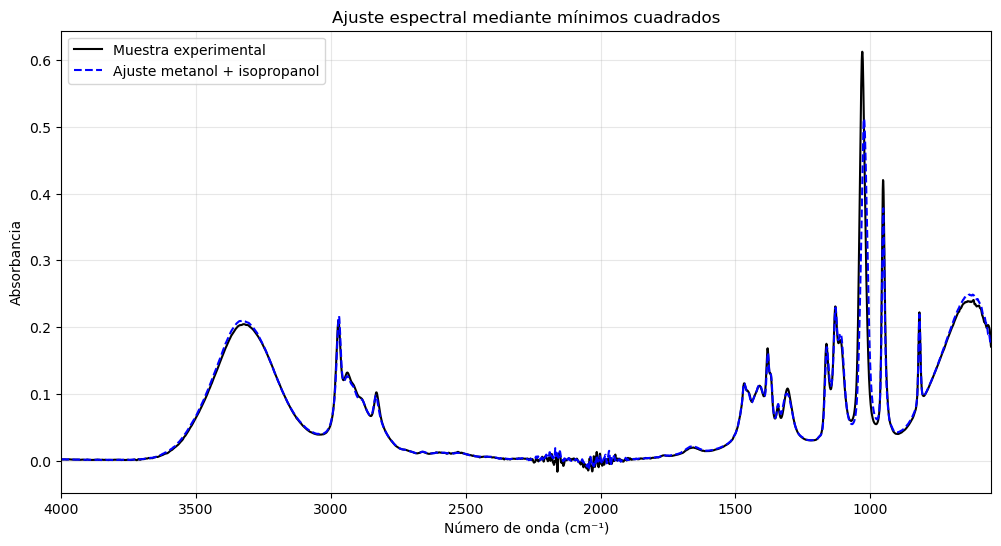

In [ ]:
#Código desarrollado en Python para estimar las contribuciones relativas de metanol e isopropanol en una muestra desconocida mediante el análisis de espectros FTIR.
#  Se utiliza el método de mínimos cuadrados no negativos (NNLS) sobre los datos de absorbancia del espectro completo para determinar los coeficientes de contribución de cada componente. 
# Además, se calculan los porcentajes relativos normalizados, el coeficiente de determinación (R²) y se compara gráficamente el espectro experimental con el reconstruido mediante el ajuste.

# Extraemos las absorbancias experimentales
A_met = metanol["Absorbancia"].to_numpy()
A_iso = isopropanol["Absorbancia"].to_numpy()
A_muestra = muestra["Absorbancia"].to_numpy()

# Matriz de absorbancias de referencia
M = np.column_stack([A_met, A_iso])

# Ajuste mediante mínimos cuadrados no negativos
coeficientes, residuo = nnls(M, A_muestra)

a, b = coeficientes

# Contribuciones relativas
porcentaje_met = 100 * a / (a + b)
porcentaje_iso = 100 * b / (a + b)

print("RESULTADOS DEL AJUSTE")
print(f"Coeficiente metanol: {a:.4f}")
print(f"Coeficiente isopropanol: {b:.4f}")
print(f"Metanol: {porcentaje_met:.2f}%")
print(f"Isopropanol: {porcentaje_iso:.2f}%")
print(f"Razón metanol/isopropanol: {a/b:.3f}")
N = len(A_muestra)

rmse = residuo / np.sqrt(N)

ss_tot = np.sum((A_muestra - np.mean(A_muestra))**2)

R2 = 1 - residuo**2 / ss_tot
print(f"R²: {R2:.5f}")

# Reconstruimos el espectro
A_ajuste = M @ coeficientes

# Comparación gráfica
plt.figure(figsize=(12, 6))

plt.plot(muestra["cm-1"], A_muestra,
         label="Muestra experimental",
         color="black", linewidth=1.5)

plt.plot(muestra["cm-1"], A_ajuste,
         label="Ajuste metanol + isopropanol",
         color="blue", linestyle="--")

plt.xlim(4000, 550)
plt.xlabel("Número de onda (cm⁻¹)")
plt.ylabel("Absorbancia")
plt.title("Ajuste espectral mediante mínimos cuadrados")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

